In [44]:
from rocketpy import Rocket, SolidMotor, Environment, Flight
import numpy as np
import pandas as pd
import datetime
import matplotlib.pyplot as plt

In [45]:
# ---- Mass properties (rocket WITHOUT motor) ----------------------------------
DRY_MASS = 20.212                   
DRY_CG = 1.761                     
DRY_INERTIA = (11.05, 11.05, 0.104)  

# ---- Body --------------------------------------------------------------------
BODY_RADIUS = 0.078359             
ROCKET_LENGTH = 3.002915     

# ---- Motor: AeroTech M2500T (98 mm, 751 mm long) ----------------------------
MOTOR_TOTAL_MASS = 8.064
MOTOR_PROPELLANT_MASS = 4.659
MOTOR_DRY_MASS = MOTOR_TOTAL_MASS - MOTOR_PROPELLANT_MASS 
MOTOR_LENGTH = 0.751
MOTOR_RADIUS = 0.049
MOTOR_BURN_TIME = 4.264 

# Thrust curve for the M2500T Motor:
THRUST_CURVE = np.vstack([[0, 0], np.array([l.split() for l in open("AeroTech_M2500T.eng") if l.strip()[:1].isdigit()], float)])

# ---- Nose cone ---------------------------------------------------------------
NOSE_LENGTH = 0.78359
NOSE_KIND = "vonKarman"            
NOSE_POSITION = 0.0

# ---- Fins (trapezoidal, x3) --------------------------------------------------
FIN_COUNT = 3
FIN_ROOT_CHORD = 0.193675
FIN_TIP_CHORD = 0.0254
FIN_SPAN = 0.2413
FIN_SWEEP_LENGTH = 0.168275
FIN_POSITION = 2.778125           
FIN_CANT = 0.0

# ---- Boat tail ---------------------------------------------------------------
TAIL_TOP_RADIUS = 0.078359
TAIL_BOTTOM_RADIUS = 0.057404
TAIL_LENGTH = 0.1651
TAIL_POSITION = 2.837815            

# ---- Rail buttons (approximate) ----------------------------------------------
RAIL_BUTTON_UPPER = 1.733
RAIL_BUTTON_LOWER = 2.273
RAIL_BUTTON_ANGLE = 150.0           

# ---- Motor  ------------------------------------------------------------------
MOTOR_POSITION = ROCKET_LENGTH + 0.0127   
N_GRAINS = 4
GRAIN_R_OUT = 0.0400
GRAIN_R_IN = 0.0160
GRAIN_H = 0.160
GRAIN_SEP = 0.004
GRAIN_VOL = np.pi * (GRAIN_R_OUT**2 - GRAIN_R_IN**2) * GRAIN_H * N_GRAINS
GRAIN_DENSITY = MOTOR_PROPELLANT_MASS / GRAIN_VOL
case_I_long = MOTOR_DRY_MASS * (3 * MOTOR_RADIUS**2 + MOTOR_LENGTH**2) / 12
case_I_roll = MOTOR_DRY_MASS * MOTOR_RADIUS**2 / 2

# ---- Recovery (from the .ork file) ------------------------------------------
def cd_s(cd, diameter):
    return cd * np.pi * diameter**2 / 4

DROGUE_CDS = cd_s(1.55, 0.9144)   # Fruity Chutes CFC-036, 36 in elliptical
PILOT_CDS  = cd_s(0.97, 0.6096)   # Rocketman LS-02, 24 in pilot
MAIN_CDS   = cd_s(2.20, 1.8288)   # Fruity Chutes IFC-072, 72 in Iris Ultra

# ---- Cd data from RASAeroII -------------------------------------------------
CD = pd.read_excel("RASAeroII Cd Data.xlsx", header=None, usecols=[0, 1]).to_numpy(float).tolist()

AFC_Drag_Data = pd.read_excel("airbrake_cd.xlsx").to_numpy(float)


Gravity Details

Acceleration of gravity at surface level:    9.7922 m/s²
Acceleration of gravity at  78.913 km (ASL): 9.5558 m/s²


Launch Site Details

Launch Date: 2026-11-04 12:00:00 UTC
Launch Site Latitude: 31.99000°
Launch Site Longitude: -102.07000°
Reference Datum: SIRGAS2000
Launch Site UTM coordinates: 209929.28 W    3543446.67 N
Launch Site UTM zone: 13R
Launch Site Surface Elevation: 851.2 m


Atmospheric Model Details

Atmospheric Model Type: Forecast
Forecast Maximum Height: 78.913 km
Forecast Time Period: from 2026-10-27 00:00:00 to 2026-11-19 12:00:00 utc
Forecast Hour Interval: 3 hrs
Forecast Latitude Range: From 90.0° to -90.0°
Forecast Longitude Range: From 0.0° to 359.75°

Surface Atmospheric Conditions

Surface Wind Speed: 3.62 m/s
Surface Wind Direction: 136.55°
Surface Wind Heading: 316.55°
Surface Pressure: 918.49 hPa
Surface Temperature: 285.66 K
Surface Air Density: 1.120 kg/m³
Surface Speed of Sound: 338.82 m/s


Earth Model Details

Earth Radius at Launch 

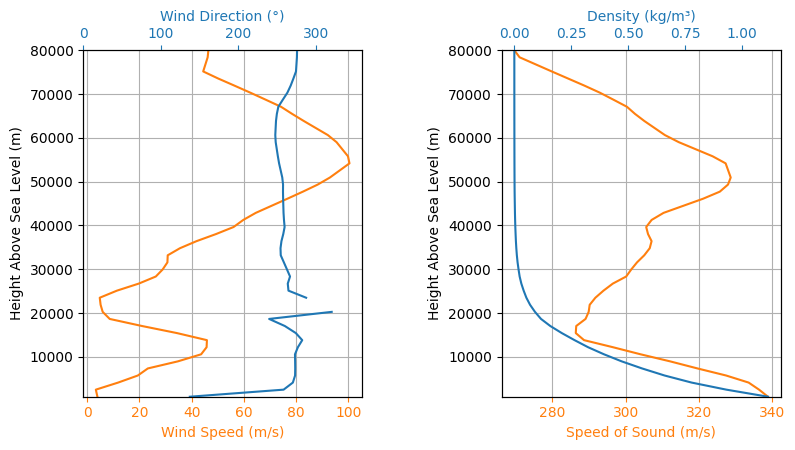

In [46]:
env = Environment(
    latitude=31.99, 
    longitude=-102.07, 
    elevation=890
    )

tomorrow = datetime.date.today() + datetime.timedelta(days=1)

env.set_date(
    (tomorrow.year, tomorrow.month, tomorrow.day, 12)
)

env.set_atmospheric_model(
    type="Forecast", 
    file="GFS"
    )

env.info()

Nozzle Details
Nozzle Radius: 0.033 m
Nozzle Throat Radius: 0.016 m

Grain Details
Number of Grains: 4
Grain Spacing: 0.004 m
Grain Density: 1724.1045383769072 kg/m3
Grain Outer Radius: 0.04 m
Grain Inner Radius: 0.016 m
Grain Height: 0.16 m
Grain Volume: 0.001 m3
Grain Mass: 1.165 kg

Motor Details
Total Burning Time: 4.264 s
Total Propellant Mass: 4.659 kg
Structural Mass Ratio: 0.422
Average Propellant Exhaust Velocity: 2054.731 m/s
Average Thrust: 2245.074 N
Maximum Thrust: 2861.69 N at 1.252 s after ignition.
Total Impulse: 9572.994 Ns



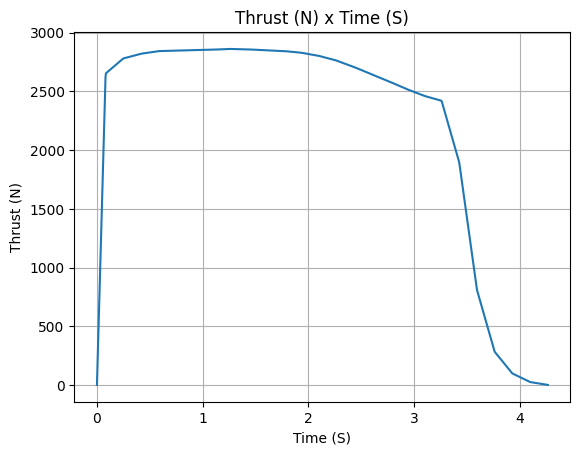

In [47]:
M2500T = SolidMotor(
    thrust_source=THRUST_CURVE,
    burn_time=MOTOR_BURN_TIME,
    dry_mass=MOTOR_DRY_MASS,
    dry_inertia=(case_I_long, case_I_long, case_I_roll),
    center_of_dry_mass_position=MOTOR_LENGTH / 2,
    grains_center_of_mass_position=MOTOR_LENGTH / 2,
    grain_number=N_GRAINS,
    grain_density=GRAIN_DENSITY,
    grain_outer_radius=GRAIN_R_OUT,
    grain_initial_inner_radius=GRAIN_R_IN,
    grain_initial_height=GRAIN_H,
    grain_separation=GRAIN_SEP,
    nozzle_radius=0.033,
    throat_radius=0.016,
    nozzle_position=0.0,
    coordinate_system_orientation="nozzle_to_combustion_chamber",
)

M2500T.info()

In [48]:
# Controller Function from RocketPy Documentation


TARGET_APOGEE_FT = 10000
MAX_RATE = 0.5          
G = 9.80665
CD_ROCKET = np.array(CD)

def controller_function(time, sampling_rate, state, state_history, observed_variables,
                        air_brakes, sensors, environment):
    # state = [x, y, z, vx, vy, vz, ...]; state_history rows = [t, x, y, z, vx, vy, vz, ...]
    altitude_ASL = state[2]
    vx, vy, vz = state[3], state[4], state[5]

    wind_x, wind_y = environment.wind_velocity_x(altitude_ASL), environment.wind_velocity_y(altitude_ASL)
    free_stream_speed = ((wind_x - vx)**2 + (wind_y - vy)**2 + vz**2) ** 0.5
    mach_number = free_stream_speed / environment.speed_of_sound(altitude_ASL)

    if time < M2500T.burn_out_time or vz <= 0:        # only between burnout and apogee
        air_brakes.deployment_level = 0
        return time, 0, 0

    # Predicted apogee with the brakes held where they are (quadratic drag, vertical coast)
    rho  = environment.density(altitude_ASL)
    mass = rocket.total_mass(time)
    cd   = np.interp(mach_number, CD_ROCKET[:, 0], CD_ROCKET[:, 1]) \
           + air_brakes.drag_coefficient(air_brakes.deployment_level, mach_number)
    k = 0.5 * rho * cd * np.pi * BODY_RADIUS**2
    apogee_pred = altitude_ASL + mass / (2 * k) * np.log(1 + k * vz**2 / (mass * G)) - environment.elevation
    error = apogee_pred - TARGET_APOGEE_FT / 3.28084   # [m], > 0 means too high

    # Proportional command, rate-limited like the docs example
    new_level = air_brakes.deployment_level + 0.002 * error
    max_change = MAX_RATE / sampling_rate
    new_level = min(max(new_level, air_brakes.deployment_level - max_change),
                    air_brakes.deployment_level + max_change)
    air_brakes.deployment_level = min(max(new_level, 0), 1)

    return (time, air_brakes.deployment_level,
            air_brakes.drag_coefficient(air_brakes.deployment_level, mach_number))

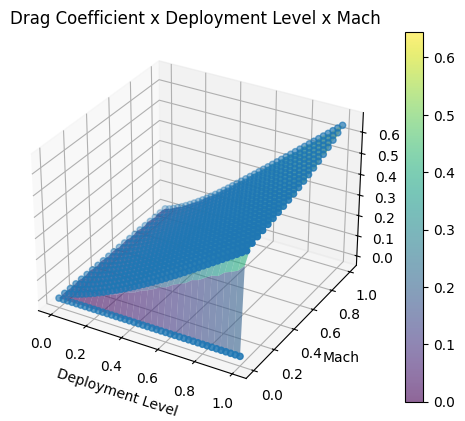

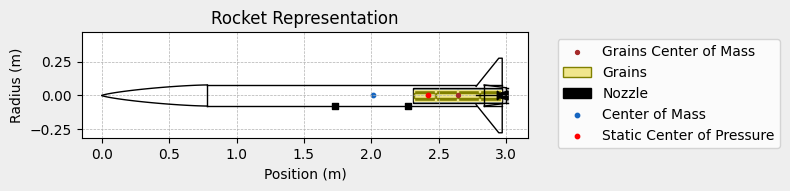

In [49]:
rocket = Rocket(
    radius=BODY_RADIUS,
    mass=DRY_MASS,
    inertia=DRY_INERTIA,
    power_off_drag=CD,
    power_on_drag=CD,
    center_of_mass_without_motor=DRY_CG,
    coordinate_system_orientation="nose_to_tail",
    )
rocket.add_nose(
    length=NOSE_LENGTH, 
    kind=NOSE_KIND,
    position=NOSE_POSITION, name="Nose Cone"
    )
rocket.add_trapezoidal_fins(
    n=FIN_COUNT,
    root_chord=FIN_ROOT_CHORD,
    tip_chord=FIN_TIP_CHORD,
    span=FIN_SPAN,
    sweep_length=FIN_SWEEP_LENGTH,
    position=FIN_POSITION,
    cant_angle=FIN_CANT,
    name="Fins",
    )
rocket.add_tail(
    top_radius=TAIL_TOP_RADIUS,
    bottom_radius=TAIL_BOTTOM_RADIUS,
    length=TAIL_LENGTH,
    position=TAIL_POSITION,
    name="Boat Tail"
    )
rocket.set_rail_buttons(
    upper_button_position=RAIL_BUTTON_UPPER,
    lower_button_position=RAIL_BUTTON_LOWER,
    angular_position=RAIL_BUTTON_ANGLE
    )
rocket.add_motor(
    M2500T, 
    position=MOTOR_POSITION
    )
rocket.add_parachute(
    "Drogue", 
    cd_s=DROGUE_CDS, 
    trigger="apogee", 
    lag=0.0
    )
rocket.add_parachute(
    "Main", 
    cd_s=DROGUE_CDS + PILOT_CDS + MAIN_CDS,
    trigger=457.2, lag=1.0
    ) 
air_brakes = rocket.add_air_brakes(
    drag_coefficient_curve=AFC_Drag_Data,
    controller_function=controller_function,
    sampling_rate=10,
    reference_area=None,
    clamp=True,
    initial_observed_variables=[0, 0, 0],
    override_rocket_drag=False,
    name="Air Brakes"
)

air_brakes.all_info()
rocket.draw()
#rocket.plots.static_margin()


Burn out State

Burn out time: 4.264 s
Altitude at burn out: 1638.228 m (ASL) | 787.028 m (AGL)
Rocket speed at burn out: 301.654 m/s
Freestream velocity at burn out: 301.680 m/s
Mach Number at burn out: 0.893
Kinetic energy at burn out: 1.075e+06 J

Apogee State

Apogee Time: 23.569 s
Apogee Altitude: 3927.080 m (ASL) | 3075.880 m (AGL)
Apogee Freestream Speed: 0.962 m/s
Apogee X position: 270.377 m
Apogee Y position: 23.538 m
Apogee latitude: 31.9902116°
Apogee longitude: -102.0671336°


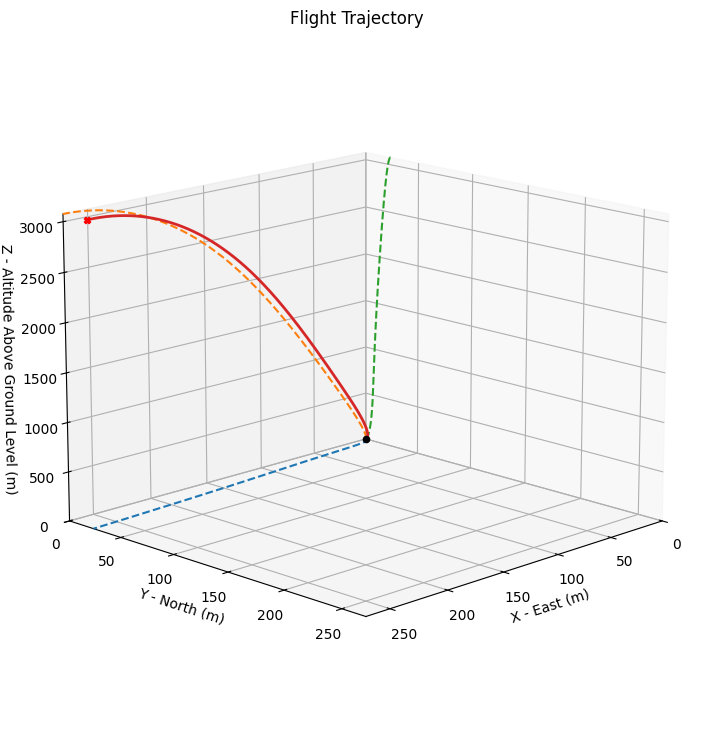

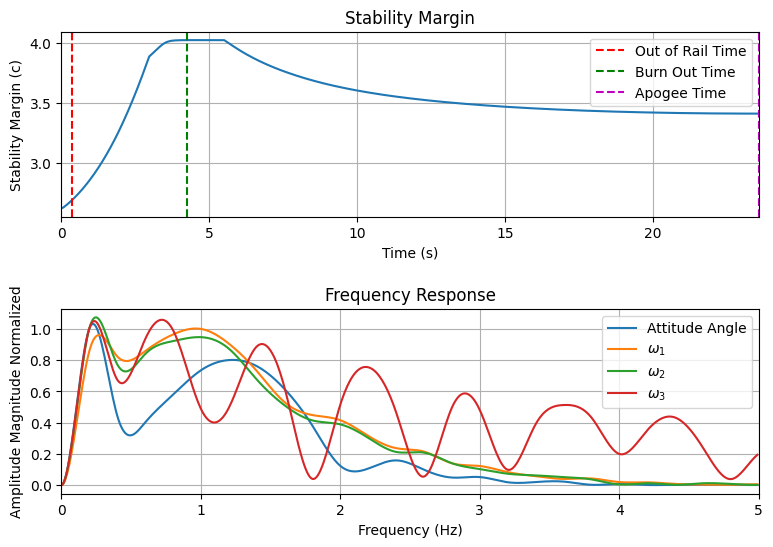

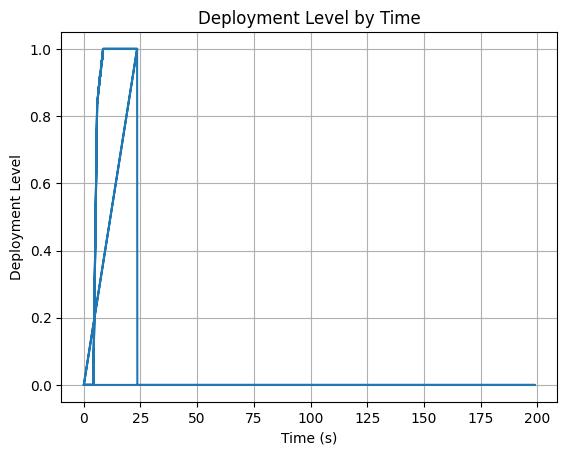

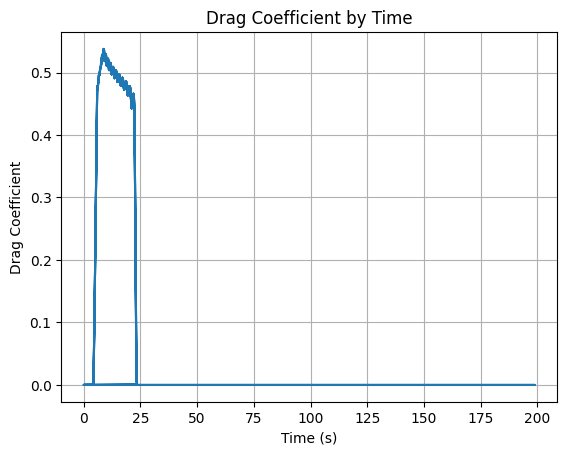

In [54]:
test_flight = Flight(
    rocket=rocket, 
    environment=env, 
    rail_length=5.2,
    inclination=87, 
    heading=0, 
    time_overshoot=False,
    terminate_on_apogee=True,
    )

test_flight.prints.burn_out_conditions()
test_flight.prints.apogee_conditions()
test_flight.plots.trajectory_3d()
test_flight.plots.stability_and_control_data()

time_list, deployment_level_list, drag_coefficient_list = [], [], []

obs_vars = test_flight.get_controller_observed_variables()

for time, deployment_level, drag_coefficient in obs_vars:
    time_list.append(time)
    deployment_level_list.append(deployment_level)
    drag_coefficient_list.append(drag_coefficient)

# Plot deployment level by time
plt.plot(time_list, deployment_level_list)
plt.xlabel("Time (s)")
plt.ylabel("Deployment Level")
plt.title("Deployment Level by Time")
plt.grid()
plt.show()

# Plot drag coefficient by time
plt.plot(time_list, drag_coefficient_list)
plt.xlabel("Time (s)")
plt.ylabel("Drag Coefficient")
plt.title("Drag Coefficient by Time")
plt.grid()
plt.show()